## 0. Setup Awal

In [1]:
import os
import time
import tracemalloc
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)

plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = 'outputLogisticRegressionL2AntiBurnout'
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

## 1. Data Understanding

### 1.1 Load Dataset

In [2]:
df = pd.read_csv('burnout_dataset1.csv')

print(f'Jumlah data awal: {len(df)}')

Jumlah data awal: 50000


### 1.2 Identifikasi Kolom yang Digunakan

In [3]:
numeric_columns = df.select_dtypes(
    include='number'
).columns

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print('Kolom Numerik:')
print(
    numeric_columns.tolist()
)

print(
    '\nKolom Kategorikal:'
)
print(
    categorical_columns.tolist()
)

Kolom Numerik:
['Person_ID', 'Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score']

Kolom Kategorikal:
['Gender', 'Country', 'Occupation', 'Education_Level', 'Employment_Status', 'Remote_Work', 'Sleep_Quality', 'Stress_Level', 'Exercise_Frequency', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Mental_Health_Status', 'AI_Wellness_Recommendation', 'Burnout_Risk']


## 2. Preprocessing

### 2.1 Seleksi Kolom

In [4]:
y = df['Burnout_Risk'].copy()

numeric_columns = numeric_columns.drop(
    ['Person_ID', 'Burnout_Score'],
    errors='ignore'
)

categorical_columns = categorical_columns.drop(
    [
        'Gender',
        'Country',
        'Occupation',
        'AI_Wellness_Recommendation',
        'Burnout_Risk',
        'Education_Level',
        'Employment_Status',
        'Mental_Health_Status'
    ],
    errors='ignore'
)

selected_columns = (
    list(numeric_columns)
    + list(categorical_columns)
)

X = df[
    selected_columns
].copy()

X.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
0,58.0,2786.0,67,3.0,7.0,4.6,74.0,75.0,26.0,18,...,Poor,High,Weekly,Yes,Yes,No,Yes,No,Yes,Average
1,24.0,8027.0,44,5.0,8.0,4.7,58.0,80.0,29.0,37,...,Poor,Moderate,Weekly,Yes,Yes,Yes,No,Yes,No,Good
2,59.0,3177.0,60,8.0,7.0,6.3,54.0,55.0,44.0,48,...,Average,Moderate,Daily,Yes,No,No,No,Yes,No,Average
3,65.0,4093.0,25,2.0,9.0,7.1,12.0,11.0,88.0,80,...,Good,Low,Weekly,Yes,No,No,No,No,Yes,Good
4,64.0,NaN,52,1.0,4.0,9.1,25.0,48.0,67.0,76,...,Excellent,Low,Never,Yes,No,No,No,Yes,No,Poor


### 2.2 Encoding Data Kategorikal

In [5]:
encoding_maps = {
    'Remote_Work': {
        'No': 0,
        'Hybrid': 1,
        'Yes': 2
    },

    'Sleep_Quality': {
        'Excellent': 0,
        'Good': 1,
        'Average': 2,
        'Poor': 3
    },

    'Stress_Level': {
        'Low': 0,
        'Moderate': 1,
        'High': 2
    },

    'Exercise_Frequency': {
        'Daily': 0,
        'Weekly': 1,
        'Rarely': 2,
        'Never': 3
    },

    'Alcohol_Consumption': {
        'No': 0,
        'Yes': 1
    },

    'Smoking': {
        'No': 0,
        'Yes': 1
    },

    'Healthy_Diet': {
        'No': 1,
        'Yes': 0
    },

    'Chronic_Stress': {
        'No': 0,
        'Yes': 1
    },

    'Family_History_Mental_Illness': {
        'No': 0,
        'Yes': 1
    },

    'Therapy_Attendance': {
        'No': 1,
        'Yes': 0
    },

    'Support_System': {
        'Poor': 3,
        'Average': 2,
        'Good': 1,
        'Excellent': 0
    },
}

for column, mapping in encoding_maps.items():

    X[column] = (
        X[column]
        .map(mapping)
    )

target_mapping = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}

y = y.map(target_mapping)

X[categorical_columns].head()

,Remote_Work,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
0,1,3,2,1,1,1,1,1,0,0.0,2
1,1,3,1,1,1,1,0,0,1,1.0,1
2,0,2,1,0,1,0,1,0,1,1.0,2
3,2,1,0,1,1,0,1,0,0,0.0,1
4,0,0,0,3,1,0,1,0,1,1.0,3


### 2.3 Penanganan Missing Values

In [6]:
print(
    'Missing value sebelum preprocessing:'
)

print(
    X.isnull().sum()
)

print(
    '\nJumlah missing value:'
)
print(X.isnull().sum().sum())

Missing value sebelum preprocessing:
Age                               250
Monthly_Income_USD               1450
Work_Hours_Per_Week                 0
Job_Satisfaction                  500
Work_Life_Balance                 650
Sleep_Hours                       950
Anxiety_Score                     800
Depression_Score                  850
Mood_Score                        900
Emotional_Stability                 0
Physical_Activity_Hours          1100
Meditation_Minutes               1200
Screen_Time_Hours                 850
Social_Media_Hours                600
Gaming_Hours                      750
Coffee_Cups_Per_Day                 0
Life_Satisfaction                 700
Productivity_Score                950
Absenteeism_Days                    0
Remote_Work                         0
Sleep_Quality                       0
Stress_Level                        0
Exercise_Frequency                  0
Alcohol_Consumption                 0
Smoking                             0
Healthy_Diet 

### 2.4 Penanganan Outlier

### 2.5 Standardisasi

Standardisasi dilakukan di dalam Pipeline pada data latih dan setiap fold cross-validation.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape

((40000, 30), (10000, 30))

### 2.6 Data Bersih

In [8]:
print('Dimensi data fitur (X):', X.shape)
print('Dimensi data latih (X_train):', X_train.shape)
print('Dimensi data uji (X_test):', X_test.shape)
print('Jumlah missing value:', X.isnull().sum().sum())
print("Kolom yang dikecualikan: Mental_Health_Status, Burnout_Score, Person_ID")
print('\nDistribusi kelas target (y):')
print(y.value_counts())

X.head()

Dimensi data fitur (X): (50000, 30)
Dimensi data latih (X_train): (40000, 30)
Dimensi data uji (X_test): (10000, 30)
Jumlah missing value: 12900
Kolom yang dikecualikan: Mental_Health_Status, Burnout_Score, Person_ID

Distribusi kelas target (y):
Burnout_Risk
0    25369
1    14780
2     9851
Name: count, dtype: int64


,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
0,58.0,2786.0,67,3.0,7.0,4.6,74.0,75.0,26.0,18,...,3,2,1,1,1,1,1,0,0.0,2
1,24.0,8027.0,44,5.0,8.0,4.7,58.0,80.0,29.0,37,...,3,1,1,1,1,0,0,1,1.0,1
2,59.0,3177.0,60,8.0,7.0,6.3,54.0,55.0,44.0,48,...,2,1,0,1,0,1,0,1,1.0,2
3,65.0,4093.0,25,2.0,9.0,7.1,12.0,11.0,88.0,80,...,1,0,1,1,0,1,0,0,0.0,1
4,64.0,NaN,52,1.0,4.0,9.1,25.0,48.0,67.0,76,...,0,0,3,1,0,1,0,1,1.0,3


## 3. Modeling

### 3.1 Inisialisasi Model Logistic Regression L2

In [9]:
pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            penalty='l2',
            solver='saga',
            max_iter=10000,
            tol=1e-4,
            random_state=42
        ))
    ]
)

param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100]
}

### 3.2 Eksekusi Model dan Pengukuran Komputasi

In [10]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring={
        'accuracy': 'accuracy',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro',
        'f1_macro': 'f1_macro',
        'f1_weighted': 'f1_weighted'
    },
    cv=cv,
    n_jobs=-1,
    refit='f1_macro',
    return_train_score=True
)

tracemalloc.start()
start_time = time.perf_counter()

search.fit(
    X_train,
    y_train
)

train_time = time.perf_counter() - start_time
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

train_memory_mb = peak / (1024 * 1024)
model = search.best_estimator_

print('Parameter terbaik:', search.best_params_)
print(f'F1 Macro Cross-Validation Terbaik: {search.best_score_:.4f}')
print(f'Waktu Eksekusi Training: {train_time:.4f} detik')
print(f'Penggunaan Memori Peak: {train_memory_mb:.4f} MB')

Parameter terbaik: {'classifier__C': 0.1}
F1 Macro Cross-Validation Terbaik: 0.7950
Waktu Eksekusi Training: 56.4391 detik
Penggunaan Memori Peak: 40.5295 MB


### 3.3 Prediksi Data Uji

In [11]:
y_pred = model.predict(
    X_test
)

df_prediksi = pd.DataFrame(
    {
        'Actual': y_test,
        'Predicted': y_pred
    },
    index=X_test.index
)

df_prediksi.head()

,Actual,Predicted
15522,2,2
35306,0,0
90,1,1
48756,0,0
19181,0,0


## 4. Evaluasi

### 4.1 Laporan Klasifikasi (Classification Report)

In [12]:
target_names = ['Low (0)', 'Moderate (1)', 'High (2)']

report = classification_report(
    y_test,
    y_pred,
    target_names=target_names,
    digits=4,
    zero_division=0
)

print(report)

              precision    recall  f1-score   support

     Low (0)     0.8997    0.8871    0.8933      5074
Moderate (1)     0.6805    0.7162    0.6979      2956
    High (2)     0.8213    0.7863    0.8034      1970

    accuracy                         0.8167     10000
   macro avg     0.8005    0.7965    0.7982     10000
weighted avg     0.8194    0.8167    0.8178     10000



### 4.2 Matriks Kebingungan (Confusion Matrix)

In [13]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[4501  573    0]
 [ 502 2117  337]
 [   0  421 1549]]


### 4.3 Metrik Evaluasi Data Uji

In [14]:
acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print(f'Accuracy           : {acc:.4f}')
print(f'Precision (Macro)  : {prec_macro:.4f}')
print(f'Recall (Macro)     : {rec_macro:.4f}')
print(f'F1-Score (Macro)   : {f1_macro:.4f}')
print(f'F1-Score (Weighted): {f1_weighted:.4f}')

Accuracy           : 0.8167
Precision (Macro)  : 0.8005
Recall (Macro)     : 0.7965
F1-Score (Macro)   : 0.7982
F1-Score (Weighted): 0.8178


### 4.4 Evaluasi Stratified 5-Fold Cross-Validation

In [15]:
cv_results = search.cv_results_
best_index = search.best_index_

cv_metric_names = {
    'Accuracy': 'accuracy',
    'Precision (Macro)': 'precision_macro',
    'Recall (Macro)': 'recall_macro',
    'F1-Score (Macro)': 'f1_macro',
    'F1-Score (Weighted)': 'f1_weighted'
}

cv_rows = []
for fold in range(5):
    row = {'Fold': f'Fold {fold + 1}'}
    for metric_name, scorer_name in cv_metric_names.items():
        key = f'split{fold}_test_{scorer_name}'
        if key in cv_results:
            row[metric_name] = cv_results[key][best_index]
    cv_rows.append(row)

df_cv = pd.DataFrame(cv_rows)
df_cv.loc['Mean'] = ['Mean'] + [df_cv[col].mean() for col in df_cv.columns[1:]]
df_cv.loc['Std'] = ['Std'] + [df_cv[col].std() for col in df_cv.columns[1:]]
df_cv

,Fold,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted)
0,Fold 1,0.814750,0.800776,0.791436,0.795327,0.816089
1,Fold 2,0.819875,0.805084,0.796085,0.800216,0.820150
2,Fold 3,0.815875,0.802800,0.793527,0.797622,0.816747
3,Fold 4,0.809500,0.795898,0.784893,0.789422,0.810940
4,Fold 5,0.811375,0.797871,0.787353,0.792166,0.811602
Mean,Mean,0.814275,0.800486,0.790659,0.794951,0.815106
Std,Std,0.003615,0.003301,0.004061,0.003829,0.003427


### 4.5 Ringkasan Waktu Eksekusi dan Penggunaan Memori

In [16]:
df_runtime = pd.DataFrame(
    [
        {
            'Model': 'Logistic Regression L2',
            'Training_Time_Seconds': round(train_time, 4),
            'Peak_Memory_MB': round(train_memory_mb, 4)
        }
    ]
)

df_runtime

,Model,Training_Time_Seconds,Peak_Memory_MB
0,Logistic Regression L2,56.4391,40.5295


### 4.6 Ringkasan Evaluasi Model

In [17]:
best_params = search.best_params_

penalty_label = 'l2'
l1_ratio_value = np.nan
C_value = best_params['classifier__C']

if 'classifier__l1_ratio' in best_params:
    l1_ratio_value = best_params['classifier__l1_ratio']

evaluation_result = pd.DataFrame(
    {
        'Model': ['Logistic Regression L2'],
        'Feature_Count': [X.shape[1]],
        'Excluded_Feature': ['Mental_Health_Status'],
        'Penalty': [penalty_label],
        'L1_Ratio': [l1_ratio_value],
        'C': [C_value],
        'Accuracy': [round(acc, 4)],
        'Precision_Macro': [round(prec_macro, 4)],
        'Recall_Macro': [round(rec_macro, 4)],
        'F1_Score_Macro': [round(f1_macro, 4)],
        'F1_Score_Weighted': [round(f1_weighted, 4)],
        'CV_5Fold_Accuracy_Mean': [round(search.cv_results_['mean_test_accuracy'][search.best_index_], 4)],
        'CV_5Fold_F1_Macro_Mean': [round(search.best_score_, 4)],
        'Training_Time_s': [round(train_time, 4)],
        'Peak_Memory_MB': [round(train_memory_mb, 4)]
    }
)

evaluation_result

,Model,Feature_Count,Excluded_Feature,Penalty,L1_Ratio,C,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB
0,Logistic Regression L2,30,Mental_Health_Status,l2,NaN,0.1,0.8167,0.8005,0.7965,0.7982,0.8178,0.8143,0.795,56.4391,40.5295


## 5. Visualisasi Hasil

### 5.1 Visualisasi Confusion Matrix Heatmap

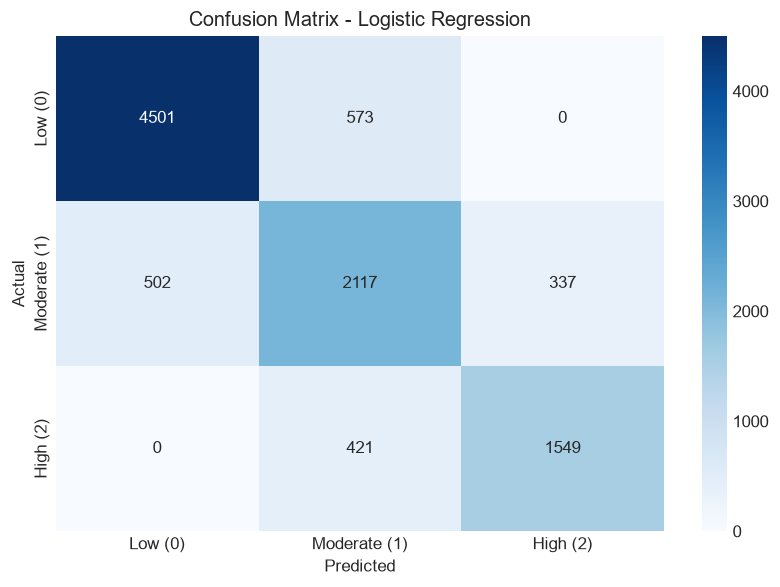

In [18]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names
)
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/confusion_matrix_logistic_regression.png'
)
plt.show()

### 5.2 Visualisasi Distribusi Kelas Prediksi vs Aktual

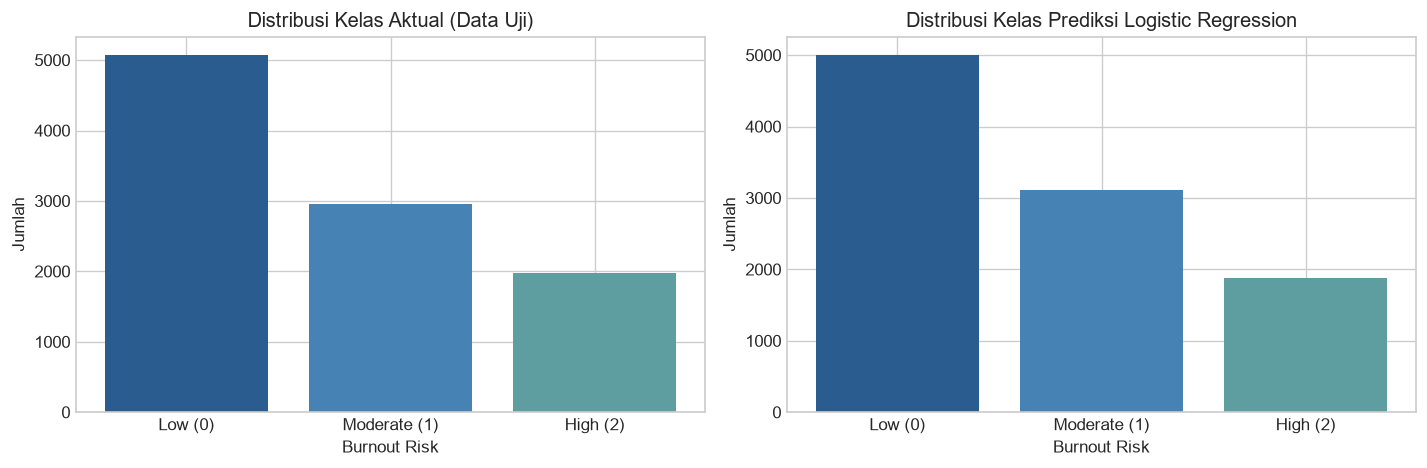

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

actual_counts = y_test.value_counts().reindex([0, 1, 2], fill_value=0)
predicted_counts = pd.Series(y_pred).value_counts().reindex([0, 1, 2], fill_value=0)

axes[0].bar(target_names, actual_counts.values, color=['#2b5c8f', '#4682b4', '#5f9ea0'])
axes[0].set_title('Distribusi Kelas Aktual (Data Uji)')
axes[0].set_xlabel('Burnout Risk')
axes[0].set_ylabel('Jumlah')

axes[1].bar(target_names, predicted_counts.values, color=['#2b5c8f', '#4682b4', '#5f9ea0'])
axes[1].set_title('Distribusi Kelas Prediksi Logistic Regression')
axes[1].set_xlabel('Burnout Risk')
axes[1].set_ylabel('Jumlah')

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/distribution_actual_vs_predicted_logistic_regression.png'
)
plt.show()

### 5.3 Visualisasi Metrik Evaluasi Stratified 5-Fold Cross-Validation

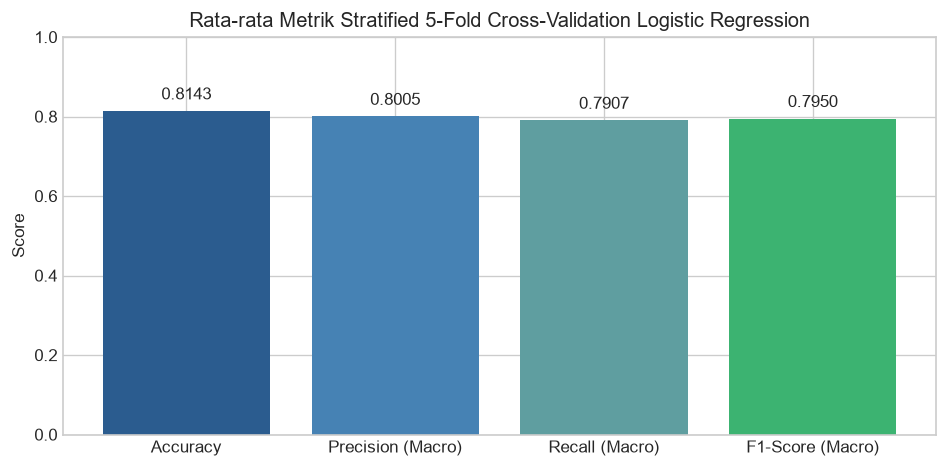

In [20]:
metrics_cv = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)']
cv_means = [
    search.cv_results_['mean_test_accuracy'][search.best_index_],
    search.cv_results_['mean_test_precision_macro'][search.best_index_],
    search.cv_results_['mean_test_recall_macro'][search.best_index_],
    search.cv_results_['mean_test_f1_macro'][search.best_index_]
]

plt.figure(figsize=(8, 4))
bars = plt.bar(
    metrics_cv,
    cv_means,
    color=['#2b5c8f', '#4682b4', '#5f9ea0', '#3cb371']
)
plt.title('Rata-rata Metrik Stratified 5-Fold Cross-Validation Logistic Regression')
plt.ylabel('Score')
plt.ylim(0, 1)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.02,
        f'{yval:.4f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/cv_metrics_logistic_regression.png'
)
plt.show()

## 6. Analisis

### 6.1 Analisis Koefisien Fitur Model Logistic Regression

In [21]:
classifier = model.named_steps['classifier']

feature_names = X.columns.tolist()
class_names = [f'Class_{name}' for name in target_names]

df_coef = pd.DataFrame(
    classifier.coef_,
    columns=feature_names,
    index=class_names
)

df_coef.T.head(10)

,Class_Low (0),Class_Moderate (1),Class_High (2)
Age,-0.014951,0.002960,0.011991
Monthly_Income_USD,-0.017686,-0.000054,0.017740
Work_Hours_Per_Week,-0.212627,0.000638,0.211989
Job_Satisfaction,0.002015,0.010958,-0.012973
Work_Life_Balance,-0.003181,-0.010219,0.013400
Sleep_Hours,-0.049047,-0.017087,0.066134
Anxiety_Score,-1.372884,0.138385,1.234499
Depression_Score,-1.388020,0.023652,1.364369
Mood_Score,0.882654,-0.080177,-0.802478
Emotional_Stability,0.410814,0.138465,-0.549279


### 6.2 Visualisasi 10 Fitur Terpenting Berdasarkan Nilai Koefisien Absolut

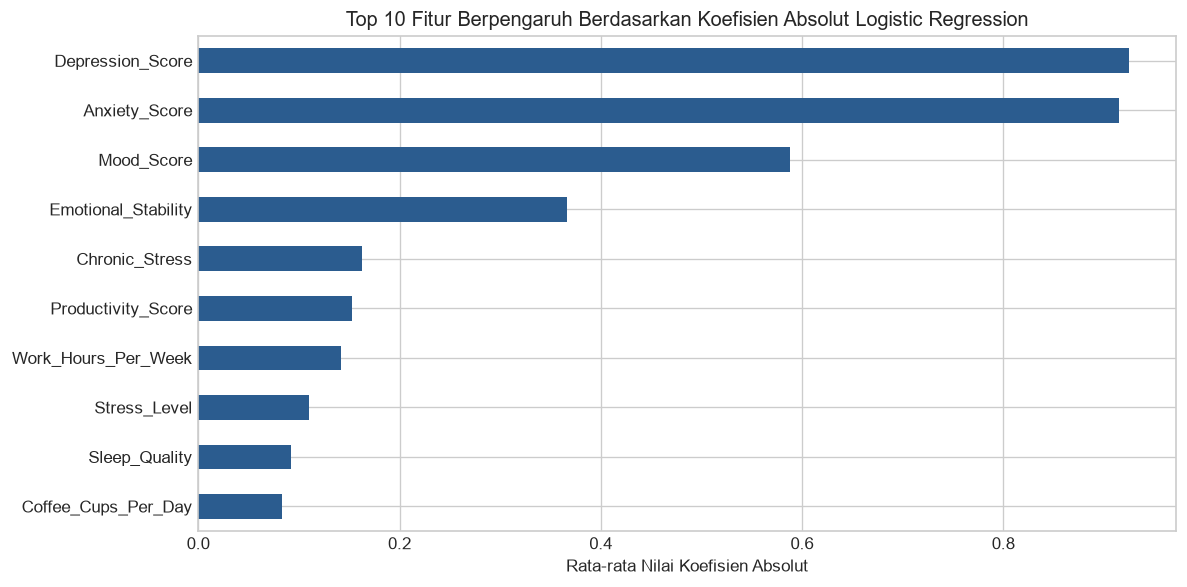

In [22]:
top_features = np.abs(classifier.coef_).mean(axis=0)
top_features_series = pd.Series(
    top_features,
    index=X.columns
).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
top_features_series.plot(
    kind='barh',
    color='#2b5c8f'
)
plt.title('Top 10 Fitur Berpengaruh Berdasarkan Koefisien Absolut Logistic Regression')
plt.xlabel('Rata-rata Nilai Koefisien Absolut')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/top_features_logistic_regression.png'
)
plt.show()

## 7. Ekspor File

### 7.1 Ekspor Ringkasan Evaluasi

In [23]:
evaluation_result.to_csv(
    f'{OUTPUT_DIR}/metrics_logistic_regression_l2.csv',
    index=False
)

### 7.2 Ekspor Hasil Prediksi Data Uji

In [24]:
df_prediksi.to_csv(
    f'{OUTPUT_DIR}/predictions_logistic_regression_l2.csv'
)

### 7.3 Ekspor Hasil 5-Fold Cross-Validation

In [25]:
df_cv.to_csv(
    f'{OUTPUT_DIR}/cv_5fold_logistic_regression_l2.csv',
    index=False
)